In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:

# Wczytanie danych (załóżmy, że to plik CSV, jeśli Excel użyj pd.read_excel)
df = pd.read_csv('dane_z_badan_dzwignicy.csv')

# Sprawdzenie podstawowych informacji o kolumnach i brakach danych
print(df.info())

# Wyświetlenie 5 pierwszych wierszy
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 948 entries, 0 to 947
Data columns (total 17 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   Nr. Pomiaru                                             948 non-null    int64  
 1   Data                                                    948 non-null    str    
 2   Ciężar ładunku [T]                                      948 non-null    int64  
 3   Długość wysięgnika [m]                                  948 non-null    float64
 4   Odległość od osi [m]                                    948 non-null    int64  
 5   Wysokość podnoszenia [m]                                948 non-null    int64  
 6   Maksymalne, chwilowe zużycie ON [l/h]                   117 non-null    float64
 7   Dzienne zużycie ON [l/8h]                               117 non-null    float64
 8   Cena hurtowa ON 1000l [PLN]                        

,Nr. Pomiaru,Data,Ciężar ładunku [T],Długość wysięgnika [m],Odległość od osi [m],Wysokość podnoszenia [m],"Maksymalne, chwilowe zużycie ON [l/h]",Dzienne zużycie ON [l/8h],Cena hurtowa ON 1000l [PLN],"Maksymalne, chwilowe zużycie energii elektrycznej [kW]",Dzienne zużycie energii elektrycznej [kW/8h],Cena energii elektrycznej [kWh],Koszt dzienny [PLN],Prędkość wiatru [km/h],Prędkość wiatru [m/s],Temperatura [C],Ciśnienie [hPa]
0,1,11/4/2019,5,13.2,2,8,15.0,48.0,NaN,NaN,NaN,NaN,NaN,10.25,2.85,10.25,995.0
1,2,11/4/2019,8,13.2,2,8,15.0,48.0,NaN,NaN,NaN,NaN,NaN,10.25,2.85,10.25,995.0
2,3,11/4/2019,15,13.2,2,8,15.0,48.0,NaN,NaN,NaN,NaN,NaN,10.25,2.85,10.25,995.0
3,4,11/5/2019,5,13.2,1,10,14.9,47.2,4241.0,NaN,NaN,NaN,200.1752,7.00,1.94,8.00,999.5
4,5,11/5/2019,8,13.2,1,10,14.9,47.2,4241.0,NaN,NaN,NaN,200.1752,7.00,1.94,8.00,999.5


In [12]:
# 1. Wyodrębnienie danych tylko dla silnika elektrycznego
# (odrzucamy wiersze, gdzie brakuje danych o zużyciu energii)
df_elec = df[df['Dzienne zużycie energii elektrycznej [kW/8h]'].notna()].copy()

# Skoro mamy tylko prąd, kolumny o Dieslu są nam niepotrzebne (mają same NaN)
kolumny_diesel = ['Maksymalne, chwilowe zużycie ON [l/h]',
                  'Dzienne zużycie ON [l/8h]',
                  'Cena hurtowa ON 1000l [PLN]']
df_elec = df_elec.drop(columns=kolumny_diesel)

# 2. Usunięcie zduplikowanej informacji o wietrze (zostawiamy km/h)
df_elec = df_elec.drop(columns=['Prędkość wiatru [m/s]'])

# 3. Przetworzenie kolumny 'Data'
df_elec['Data'] = pd.to_datetime(df_elec['Data']) # Zamiana tekstu na typ daty
df_elec['Miesiąc'] = df_elec['Data'].dt.month     # Ekstrakcja samego miesiąca (1-12)

# Usuwamy oryginalną datę (model ML potrzebuje liczb) oraz 'Nr. Pomiaru' (to tylko ID)
df_elec = df_elec.drop(columns=['Data', 'Nr. Pomiaru'])

df_elec = df_elec.drop(columns=['Cena energii elektrycznej [kWh]'])

# Sprawdzenie efektów pracy
print(df_elec.info())

<class 'pandas.DataFrame'>
RangeIndex: 831 entries, 117 to 947
Data columns (total 11 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   Ciężar ładunku [T]                                      831 non-null    int64  
 1   Długość wysięgnika [m]                                  831 non-null    float64
 2   Odległość od osi [m]                                    831 non-null    int64  
 3   Wysokość podnoszenia [m]                                831 non-null    int64  
 4   Maksymalne, chwilowe zużycie energii elektrycznej [kW]  831 non-null    float64
 5   Dzienne zużycie energii elektrycznej [kW/8h]            831 non-null    float64
 6   Koszt dzienny [PLN]                                     831 non-null    float64
 7   Prędkość wiatru [km/h]                                  831 non-null    float64
 8   Temperatura [C]                                  

In [9]:
# Ustawienie globalnego stylu wykresów (dla lepszej czytelności)
sns.set_theme(style="whitegrid")

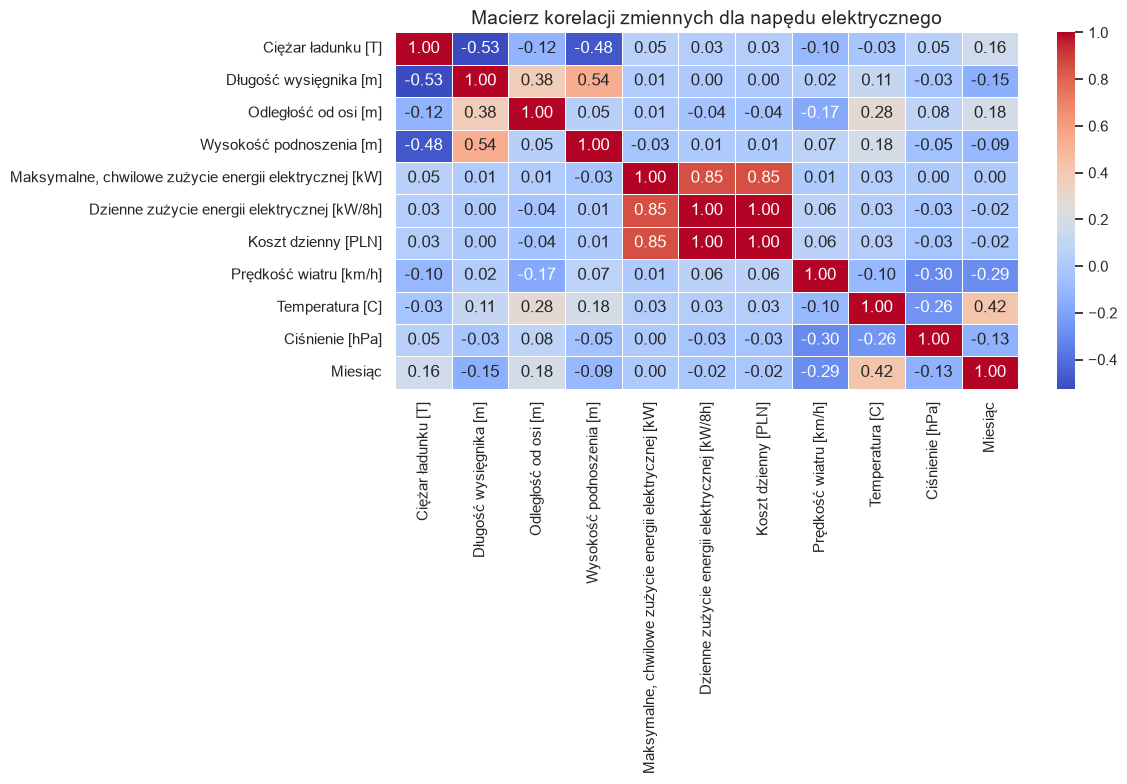

In [13]:
# ==========================================
# 1. Macierz korelacji (Heatmap)
# ==========================================
plt.figure(figsize=(12, 8))
# Obliczamy macierz korelacji Pearsona
korelacje = df_elec.corr()

# Rysujemy mapę ciepła z adnotacjami liczbowymi
sns.heatmap(korelacje, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Macierz korelacji zmiennych dla napędu elektrycznego", fontsize=14)
plt.tight_layout()
plt.show()

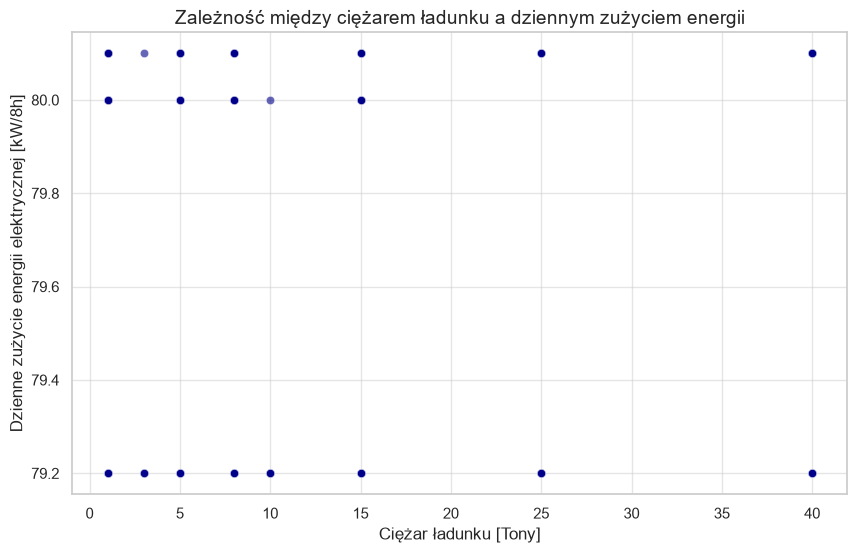

In [11]:
# ==========================================
# 2. Wykres punktowy (Scatterplot)
# ==========================================
plt.figure(figsize=(10, 6))
# Rysujemy zależność ciężaru ładunku od dziennego zużycia energii
sns.scatterplot(
    data=df_elec,
    x='Ciężar ładunku [T]',
    y='Dzienne zużycie energii elektrycznej [kW/8h]',
    alpha=0.6, # Lekka przezroczystość dla zachodzących na siebie punktów
    color="darkblue"
)
plt.title("Zależność między ciężarem ładunku a dziennym zużyciem energii", fontsize=14)
plt.xlabel("Ciężar ładunku [Tony]", fontsize=12)
plt.ylabel("Dzienne zużycie energii elektrycznej [kW/8h]", fontsize=12)
plt.show()

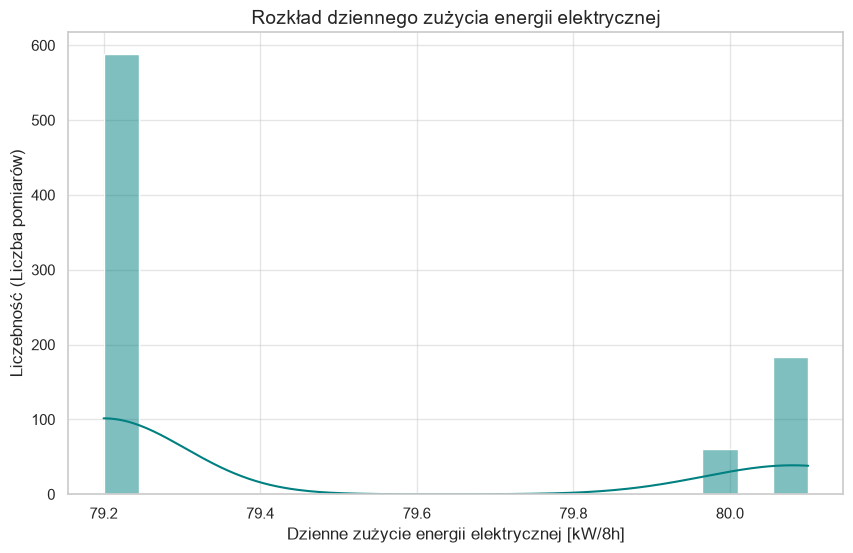

In [14]:
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df_elec,
    x='Dzienne zużycie energii elektrycznej [kW/8h]',
    kde=True,
    bins=20,
    color='teal'
)
plt.title("Rozkład dziennego zużycia energii elektrycznej", fontsize=14)
plt.xlabel("Dzienne zużycie energii elektrycznej [kW/8h]", fontsize=12)
plt.ylabel("Liczebność (Liczba pomiarów)", fontsize=12)
plt.show()